# 02 — Référence simple (Phase 3)

Histogrammes de couleur (RGB + HSV) et texture (LBP) + régression logistique / forêt aléatoire. **But : un point de référence obligatoire avant le CNN.** Si le CNN de la Phase 4 ne fait qu'égaler cette référence, c'est le signe qu'il apprend surtout la couleur de l'hôpital et pas la morphologie cellulaire.

Voir `PLAN.md` (Phase 3) et `outputs/rapport/03_reference_simple.md`.

In [1]:
# Setup
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

from src.utils import load_config, set_seed, detect_environment, evaluer_par_hopital, save_metrics

CFG = load_config()
SEED = CFG["seed"]
set_seed(SEED)
print("Environnement :", detect_environment())

Environnement : local


## 1. Données et variables

124 variables par patch : histogrammes RGB (48) + HSV (48) + LBP à deux échelles (28). Détail et justification dans `src/features.py`. L'extraction est mise en cache dans `data/interim/` : le premier appel prend quelques minutes, les suivants sont instantanés.

In [2]:
from src.data import charger_sous_echantillon, HOPITAL_LABEL
from src.features import extraire_features, indices_groupe, noms_features

df = charger_sous_echantillon(CFG)
X_tout, ids, noms = extraire_features(df)
print("X :", X_tout.shape, "| variables :", len(noms))

IDX = {
    "couleur": indices_groupe("couleur"),
    "texture": indices_groupe("texture"),
    "couleur+texture": np.arange(len(noms)),
}
print({k: len(v) for k, v in IDX.items()})

Cache trouvé : 39,000 patchs déjà calculés (features_bins16.npz)
X : (39000, 124) | variables : 124
{'couleur': 96, 'texture': 28, 'couleur+texture': 124}


## 2. Protocole

- **Entraînement** : split `train` (hôpitaux 0, 3, 4), 24 000 patchs.
- **Réglage des hyperparamètres** : `val_ood` (hôpital 1) uniquement, sur la ROC-AUC.
- **Rapporté** : `train` (en échantillon), `id_val` (mêmes lames que train, patchs tenus à l'écart) et `val_ood` (hôpital 1, hors distribution).
- **L'hôpital 2 (`test`) n'est pas touché** : il est réservé à la Phase 6, une seule fois.

Seuil de décision laissé à 0,5 ici : le choix d'un seuil orienté rappel se fait en Phase 4 sur `val_ood`, une fois le modèle principal en place.

In [3]:
SPLITS = ["train", "id_val", "val_ood"]   # 'test' volontairement absent
assert "test" not in SPLITS

masques = {s: (df.split == s).values for s in SPLITS}
y = {s: df.label.values[masques[s]] for s in SPLITS}
centres = {s: df.center.values[masques[s]] for s in SPLITS}
X = {s: X_tout[masques[s]] for s in SPLITS}

for s in SPLITS:
    print(f"{s:8s} n={len(y[s]):6,d}  hôpitaux={sorted(set(centres[s].tolist()))}  "
          f"part tumorale={y[s].mean():.3f}")

train    n=24,000  hôpitaux=[0, 3, 4]  part tumorale=0.500
id_val   n= 3,000  hôpitaux=[0, 3, 4]  part tumorale=0.500
val_ood  n= 4,000  hôpitaux=[1]  part tumorale=0.500


## 3. Réglage sur l'hôpital 1 (`val_ood`)

Deux familles de modèles × trois jeux de variables. Les hyperparamètres sont choisis sur la ROC-AUC de `val_ood` — jamais sur `train`, jamais sur l'hôpital 2.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import time

def construire(nom_modele, params):
    if nom_modele == "logreg":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=2000, random_state=SEED, **params))
    return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, **params)

GRILLES = {
    "logreg": [{"C": c} for c in (0.01, 0.1, 1.0, 10.0)],
    "rf": [{"max_depth": d, "min_samples_leaf": f}
           for d in (None, 15) for f in (1, 5)],
}

resultats = []
modeles = {}
t0 = time.time()
for variante, idx in IDX.items():
    for nom_modele, grille in GRILLES.items():
        for params in grille:
            m = construire(nom_modele, params)
            m.fit(X["train"][:, idx], y["train"])
            auc_val = roc_auc_score(y["val_ood"], m.predict_proba(X["val_ood"][:, idx])[:, 1])
            auc_id = roc_auc_score(y["id_val"], m.predict_proba(X["id_val"][:, idx])[:, 1])
            resultats.append({"variante": variante, "modele": nom_modele,
                              "params": str(params), "auc_id_val": auc_id, "auc_val_ood": auc_val})
            modeles[(variante, nom_modele, str(params))] = m
print(f"{len(resultats)} modèles entraînés en {time.time() - t0:.0f} s")

res = pd.DataFrame(resultats).round(4)
display(res.sort_values("auc_val_ood", ascending=False).head(12))

24 modèles entraînés en 188 s


,variante,modele,params,auc_id_val,auc_val_ood
23,couleur+texture,rf,"{'max_depth': 15, 'min_samples_leaf': 5}",0.9927,0.8975
22,couleur+texture,rf,"{'max_depth': 15, 'min_samples_leaf': 1}",0.9935,0.8966
21,couleur+texture,rf,"{'max_depth': None, 'min_samples_leaf': 5}",0.9933,0.8964
20,couleur+texture,rf,"{'max_depth': None, 'min_samples_leaf': 1}",0.9944,0.8958
10,texture,logreg,{'C': 1.0},0.9334,0.8881
11,texture,logreg,{'C': 10.0},0.9331,0.8881
9,texture,logreg,{'C': 0.1},0.9337,0.8877
8,texture,logreg,{'C': 0.01},0.9313,0.8825
6,couleur,rf,"{'max_depth': 15, 'min_samples_leaf': 1}",0.9921,0.8825
7,couleur,rf,"{'max_depth': 15, 'min_samples_leaf': 5}",0.9916,0.8823


In [5]:
# Meilleur jeu d'hyperparamètres par (variante, modèle), choisi sur val_ood
meilleurs = res.loc[res.groupby(["variante", "modele"]).auc_val_ood.idxmax()].reset_index(drop=True)
display(meilleurs.sort_values("auc_val_ood", ascending=False))

,variante,modele,params,auc_id_val,auc_val_ood
3,couleur+texture,rf,"{'max_depth': 15, 'min_samples_leaf': 5}",0.9927,0.8975
4,texture,logreg,{'C': 1.0},0.9334,0.8881
1,couleur,rf,"{'max_depth': 15, 'min_samples_leaf': 1}",0.9921,0.8825
2,couleur+texture,logreg,{'C': 10.0},0.9864,0.8583
5,texture,rf,"{'max_depth': 15, 'min_samples_leaf': 5}",0.9617,0.8540
0,couleur,logreg,{'C': 10.0},0.9803,0.8161


## 4. Métriques par hôpital

Pour les deux modèles retenus sur l'ensemble complet des variables (couleur + texture).

In [6]:
tables = {}
for nom_modele in ("logreg", "rf"):
    ligne = meilleurs[(meilleurs.variante == "couleur+texture") & (meilleurs.modele == nom_modele)].iloc[0]
    m = modeles[("couleur+texture", nom_modele, ligne.params)]
    idx = IDX["couleur+texture"]
    for s in SPLITS:
        p = m.predict_proba(X[s][:, idx])[:, 1]
        t = evaluer_par_hopital(y[s], p, centres[s], seuil=0.5, label_hopital=HOPITAL_LABEL)
        tables[(nom_modele, s)] = t
    print(f"=== {nom_modele} ({ligne.params}) ===")
    for s in SPLITS:
        print(f"-- {s} --")
        display(tables[(nom_modele, s)])

=== logreg ({'C': 10.0}) ===
-- train --


,hopital,n,roc_auc,rappel,precision,f1,accuracy,vn,fp,fn,vp
0,H0 (entraînement),8000,0.9781,0.9148,0.9440,0.9292,0.9302,3783,217,341,3659
1,H3 (entraînement),8000,0.9864,0.9260,0.9626,0.9439,0.9450,3856,144,296,3704
2,H4 (entraînement),8000,0.9908,0.9678,0.9551,0.9614,0.9611,3818,182,129,3871
3,ensemble,24000,0.9859,0.9362,0.9539,0.9449,0.9455,11457,543,766,11234


-- id_val --


,hopital,n,roc_auc,rappel,precision,f1,accuracy,vn,fp,fn,vp
0,H0 (entraînement),1000,0.9790,0.9100,0.9305,0.9201,0.9210,466,34,45,455
1,H3 (entraînement),1000,0.9876,0.9080,0.9598,0.9332,0.9350,481,19,46,454
2,H4 (entraînement),1000,0.9905,0.9620,0.9563,0.9591,0.9590,478,22,19,481
3,ensemble,3000,0.9864,0.9267,0.9488,0.9376,0.9383,1425,75,110,1390


-- val_ood --


,hopital,n,roc_auc,rappel,precision,f1,accuracy,vn,fp,fn,vp
0,H1 (validation hors distribution),4000,0.8583,0.7725,0.7879,0.7801,0.7822,1584,416,455,1545
1,ensemble,4000,0.8583,0.7725,0.7879,0.7801,0.7822,1584,416,455,1545


... (2 outputs left out)

-- id_val --


,hopital,n,roc_auc,rappel,precision,f1,accuracy,vn,fp,fn,vp
0,H0 (entraînement),1000,0.9913,0.9220,0.9746,0.9476,0.949,488,12,39,461
1,H3 (entraînement),1000,0.9929,0.9000,0.9868,0.9414,0.944,494,6,50,450
2,H4 (entraînement),1000,0.9945,0.9600,0.9776,0.9687,0.969,489,11,20,480
3,ensemble,3000,0.9927,0.9273,0.9796,0.9527,0.954,1471,29,109,1391


-- val_ood --


,hopital,n,roc_auc,rappel,precision,f1,accuracy,vn,fp,fn,vp
0,H1 (validation hors distribution),4000,0.8975,0.7885,0.846,0.8163,0.8225,1713,287,423,1577
1,ensemble,4000,0.8975,0.7885,0.846,0.8163,0.8225,1713,287,423,1577


## 5. Couleur ou texture ?

Deux angles complémentaires : (a) une **ablation** — que vaut le modèle avec la couleur seule, la texture seule, les deux ; (b) les **importances** de la forêt aléatoire, agrégées par famille de variables.

auc_id_val         auc_val_ood        
modele              logreg      rf      logreg      rf
variante                                              
couleur             0.9803  0.9921      0.8161  0.8825
couleur+texture     0.9864  0.9927      0.8583  0.8975
texture             0.9334  0.9617      0.8881  0.8540

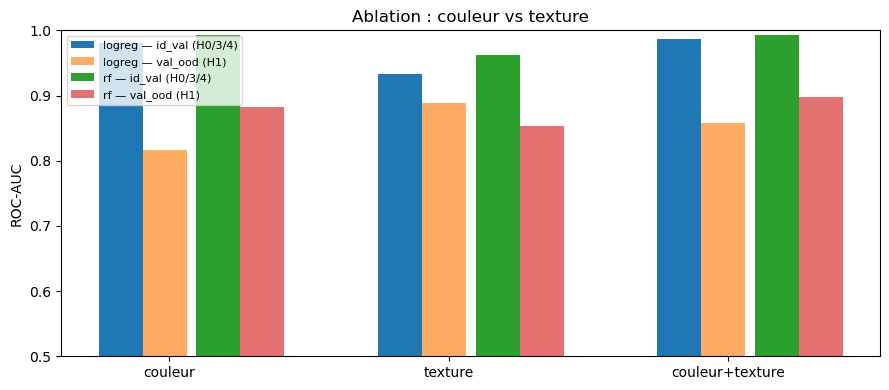

In [7]:
ablation = meilleurs.pivot(index="variante", columns="modele", values=["auc_id_val", "auc_val_ood"]).round(4)
display(ablation)

fig, ax = plt.subplots(figsize=(9, 4))
ordre = ["couleur", "texture", "couleur+texture"]
largeur, xs = 0.35, np.arange(len(ordre))
for k, nom_modele in enumerate(("logreg", "rf")):
    vals_id = [meilleurs[(meilleurs.variante == v) & (meilleurs.modele == nom_modele)].auc_id_val.iloc[0] for v in ordre]
    vals_ood = [meilleurs[(meilleurs.variante == v) & (meilleurs.modele == nom_modele)].auc_val_ood.iloc[0] for v in ordre]
    ax.bar(xs + k * largeur - largeur / 2, vals_id, largeur * 0.45, label=f"{nom_modele} — id_val (H0/3/4)")
    ax.bar(xs + k * largeur - largeur / 2 + largeur * 0.45, vals_ood, largeur * 0.45,
           label=f"{nom_modele} — val_ood (H1)", alpha=.65)
ax.set_xticks(xs); ax.set_xticklabels(ordre); ax.set_ylim(0.5, 1.0)
ax.set_ylabel("ROC-AUC"); ax.set_title("Ablation : couleur vs texture")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../outputs/figures/03_ablation_couleur_texture.png", dpi=130); plt.show()

Importance totale par famille de variables :


couleur_rgb    0.4332
couleur_hsv    0.3949
texture        0.1719
dtype: float64

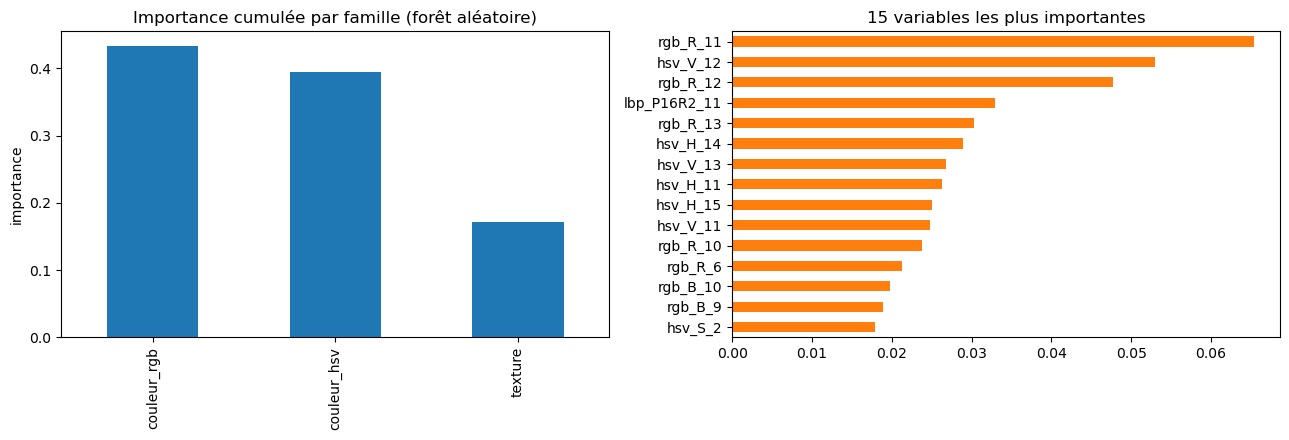

In [8]:
from src.features import groupes_features

ligne_rf = meilleurs[(meilleurs.variante == "couleur+texture") & (meilleurs.modele == "rf")].iloc[0]
rf = modeles[("couleur+texture", "rf", ligne_rf.params)]
imp = pd.Series(rf.feature_importances_, index=noms)
g = groupes_features()
par_famille = imp.groupby(imp.index.map(g)).sum().sort_values(ascending=False)
print("Importance totale par famille de variables :")
display(par_famille.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
par_famille.plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("Importance cumulée par famille (forêt aléatoire)")
axes[0].set_ylabel("importance")
imp.sort_values(ascending=False).head(15).iloc[::-1].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_title("15 variables les plus importantes")
plt.tight_layout(); plt.savefig("../outputs/figures/04_importances_reference.png", dpi=130); plt.show()

## 6. Sauvegarde des métriques

Tous les chiffres cités dans le rapport viennent de ce fichier JSON.

In [9]:
metrics = {
    "protocole": {
        "entrainement": "split train (hopitaux 0, 3, 4)",
        "reglage_hyperparametres": "val_ood (hopital 1), critere ROC-AUC",
        "seuil": 0.5,
        "hopital_2": "non utilise (reserve Phase 6)",
    },
    "n_variables": {k: int(len(v)) for k, v in IDX.items()},
    "grille_complete": res.to_dict(orient="records"),
    "meilleurs_par_variante": meilleurs.to_dict(orient="records"),
    "importances_par_famille": par_famille.round(4).to_dict(),
    "top15_variables": imp.sort_values(ascending=False).head(15).round(4).to_dict(),
    "metriques_par_hopital": {
        f"{nom_modele}__{s}": tables[(nom_modele, s)].to_dict(orient="records")
        for nom_modele in ("logreg", "rf") for s in SPLITS
    },
}
print(save_metrics(metrics, "outputs/metrics/03_reference_simple.json"))

C:\Users\Youcef Lagraa\OneDrive\Bureau\Breast Cancer\Breast_Cancer\outputs\metrics\03_reference_simple.json


## 7. Lecture des résultats

Voir `outputs/rapport/03_reference_simple.md` pour l'interprétation : écart entre hôpitaux d'entraînement et hôpital 1, part de couleur vs texture, et ce que cela implique comme exigence pour le CNN de la Phase 4.